# Transitive RL (TRL) on grid mazes

This notebook implements **Transitive Reinforcement Learning** from *"Transitive RL: Value Learning via Divide and Conquer"* (Park, Oberai, Atreya & Levine, ICLR 2026) end to end, on discrete grid mazes:

1. Background: goal-conditioned RL and the triangle inequality
2. The environment (three mazes) and BFS ground truth
3. The offline dataset
4. My TRL, the paper-faithful TRL, and the TD and Monte Carlo (MC) baselines (all tabular)
5. Training and evaluation
6. Results: learning curves, rollouts, ablations, and the paper's TRL vs our adaptations

Everything is in this one file. Requirements: `numpy` and `matplotlib`. Everything is tabular and runs on the CPU in about 30 minutes (the paper-faithful agent is the slowest part).

## 1. Background

**Offline goal-conditioned RL.** We get a dataset of reward-free trajectories and must learn a policy $\pi(a\mid s,g)$ that reaches **any** goal $g$ from **any** state $s$ in as few steps as possible, without interacting with the environment during training.

With a 0/1 "reached the goal" reward, discount $\gamma$, and deterministic dynamics, the optimal value is
$$V^*(s,g)=\gamma^{d^*(s,g)},$$
where $d^*(s,g)$ is the shortest-path distance. We learn $Q(s,a,g)=\gamma^{\text{steps to reach } g \text{ when first taking } a}$.

**Triangle inequality.** Distances satisfy $d^*(s,g)\le d^*(s,w)+d^*(w,g)$, so
$$V^*(s,g)\;\ge\;V^*(s,w)\,V^*(w,g),$$
with equality when $w$ lies on a shortest path. This gives a **divide-and-conquer** (transitive) Bellman update:
$$Q(s_i,a_i,s_j)\;\leftarrow\;\max_{k}\;Q(s_i,a_i,s_k)\cdot\max_{a'}Q(s_k,a',s_j).$$

| Method | Target for $Q(s_i,a_i,s_j)$ | Recursions for a length-$T$ path |
|---|---|---|
| TD (1-step Bellman) | $\gamma\,\max_{a'}Q(s_{i+1},a',s_j)$ | $O(T)$ |
| MC (Monte Carlo) | $\gamma^{\,j-i}$ (distance seen in the data) | 0, but high variance and only behaviour-policy values |
| **TRL** | $Q(s_i,a_i,s_k)\cdot\max_{a'}Q(s_k,a',s_j)$ | $O(\log T)$ in the best case |

**What makes TRL practical** (Section 4.2–4.3 of the paper):
* **In-trajectory subgoals.** $s_k$ is taken from the *same* dataset trajectory, $i\le k<j$, not from arbitrary states, which avoids exploiting over-estimated values.
* **Expectile regression.** Instead of an explicit max over $k$, regress with the asymmetric expectile loss (κ = 0.7 by default in the paper). Under-estimates are pushed up harder than over-estimates are pushed down, giving a "soft, in-sample max".
* **Distance re-weighting.** Each sample is weighted by $1/(1+\hat d(s_i,s_j))^{\lambda}$, so the short chunks that long ones are built from are learned first, like dynamic programming.
* **Base cases.** A chunk of length 0 or 1 gets its exact value $\gamma^0$ or $\gamma^1$.

In [1]:
import math
import time
from collections import deque

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e3"})
COLORS = {"trl": "#2a78d6", "td": "#eb6834", "mc": "#1baf7a"}
COLORS["paper"] = "#9b6bd6"
METHODS = ["trl", "paper", "td", "mc"]
LABELS = {"trl": "My method (TRL, exact max)", "paper": "Paper-faithful TRL", "td": "TD learning (one step)",
          "mc": "Monte Carlo"}

from IPython.display import Markdown, display


def show_table(headers, rows, title=None):
    # Show results as a readable table in the notebook.

    lines = ([f"**{title}**", ""] if title else []) + ["| " + " | ".join(headers) + " |",
                                                      "|" + "---|" * len(headers)]
    lines += ["| " + " | ".join(str(v) for v in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))

## 2. The environment

States are the free cells of a maze, there are 4 actions (up, down, left, right), and moving into a wall leaves the agent in place. We compute exact shortest-path distances with BFS, to use as ground truth for evaluation only.

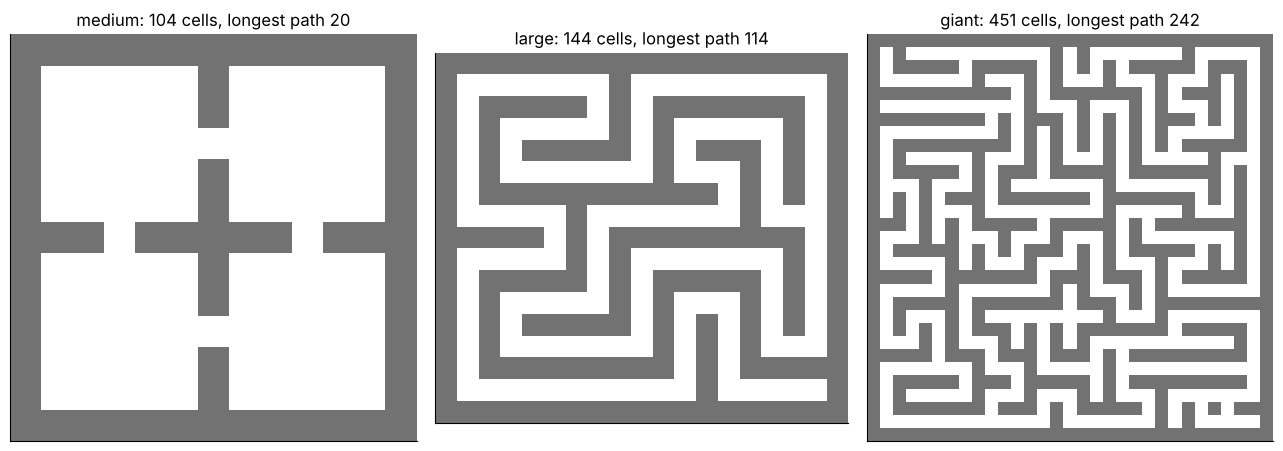

In [2]:
LAYOUTS = {
    # 4-rooms style, shortest paths up to 20 steps.
    "medium": [
        "#############",
        "#.....#.....#",
        "#.....#.....#",
        "#...........#",
        "#.....#.....#",
        "#.....#.....#",
        "###.#####.###",
        "#.....#.....#",
        "#.....#.....#",
        "#...........#",
        "#.....#.....#",
        "#.....#.....#",
        "#############",
    ],
    # Long corridors, shortest paths up to 114 steps.
    "large": [
        "###################",
        "#.......#.........#",
        "#.#####.#.#######.#",
        "#.#.....#.#.....#.#",
        "#.#.#####.#.###.#.#",
        "#.#.......#...#.#.#",
        "#.###########.#.#.#",
        "#.....#.......#...#",
        "#####.#.#########.#",
        "#.....#.#.......#.#",
        "#.#####.#.#####.#.#",
        "#.#.....#.#...#.#.#",
        "#.#.#####.#.#.#.#.#",
        "#.#.......#.#.#...#",
        "#.#########.#.#####",
        "#...........#.....#",
        "###################",
    ],
}


def generate_maze(cells_h, cells_w, extra_openings=2, seed=1):
    """Random depth-first-search maze (long winding corridors) with a few loops."""
    rng = np.random.default_rng(seed)
    H, W = 2 * cells_h + 1, 2 * cells_w + 1
    g = np.ones((H, W), dtype=bool)
    stack, seen = [(0, 0)], {(0, 0)}
    g[1, 1] = False
    while stack:
        r, c = stack[-1]
        nbrs = [(r + dr, c + dc) for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1))
                if 0 <= r + dr < cells_h and 0 <= c + dc < cells_w and (r + dr, c + dc) not in seen]
        if not nbrs:
            stack.pop()
            continue
        nr, nc = nbrs[rng.integers(len(nbrs))]
        g[2 * nr + 1, 2 * nc + 1] = False
        g[r + nr + 1, c + nc + 1] = False
        seen.add((nr, nc))
        stack.append((nr, nc))
    walls = [(r, c) for r in range(1, H - 1) for c in range(1, W - 1) if g[r, c] and (r % 2) != (c % 2)]
    for idx in rng.choice(len(walls), size=extra_openings, replace=False):
        g[walls[idx]] = False
    return ["".join("#" if x else "." for x in row) for row in g]


# Very long horizon: a 31x31 maze, shortest paths up to 242 steps.
LAYOUTS["giant"] = generate_maze(15, 15, extra_openings=2, seed=1)

ACTIONS = np.array([(-1, 0), (1, 0), (0, -1), (0, 1)])  # up, down, left, right
NUM_ACTIONS = len(ACTIONS)


class GridMaze:
    def __init__(self, layout="medium"):
        rows = LAYOUTS[layout]
        self.layout = layout
        self.grid = np.array([[c == "#" for c in r] for r in rows])  # True = wall
        self.cells = [tuple(p) for p in np.argwhere(~self.grid)]
        self.cell_to_id = {c: i for i, c in enumerate(self.cells)}
        self.num_states = len(self.cells)
        self.next_state = np.zeros((self.num_states, NUM_ACTIONS), dtype=np.int64)
        for s, (r, c) in enumerate(self.cells):
            for a, (dr, dc) in enumerate(ACTIONS):
                self.next_state[s, a] = self.cell_to_id.get((r + dr, c + dc), s)
        self._dist = None

    def step(self, s, a):
        return int(self.next_state[s, a])

    @property
    def dist(self):
        """True shortest-path distances d*(s, g) for all pairs, via BFS."""
        if self._dist is None:
            n = self.num_states
            d = np.full((n, n), np.inf)
            for src in range(n):
                d[src, src] = 0
                q = deque([src])
                while q:
                    u = q.popleft()
                    for v in self.next_state[u]:
                        if d[src, v] == np.inf:
                            d[src, v] = d[src, u] + 1
                            q.append(v)
            self._dist = d
        return self._dist

    def true_q_dist(self):
        """d*_Q(s, a, g): steps to reach g when first taking a (0 if s == g)."""
        dq = 1 + self.dist[self.next_state]  # (S, A, G)
        idx = np.arange(self.num_states)
        dq[idx, :, idx] = 0
        return dq


ENVS = {name: GridMaze(name) for name in ["medium", "large", "giant"]}
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))
for ax, (name, env) in zip(axes, ENVS.items()):
    ax.imshow(env.grid, cmap="Greys", vmin=0, vmax=1.6)
    ax.set_title(f"{name}: {env.num_states} cells, longest path {int(env.dist.max())}")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.tight_layout(); plt.show()

**What the picture shows.** Each panel is one maze. Dark squares are walls and light squares are open cells the agent can stand on. The title gives the number of open cells and the length of the longest shortest path, which is the hardest possible task in that maze.

## 3. The offline dataset

1,000 reward-free trajectories of 200 steps from a **noisy waypoint-following** policy, similar in spirit to OGBench's `navigate` datasets. The agent repeatedly picks a random waypoint and walks towards it along a shortest path, but takes a random action 20% of the time. No trajectory is about the test tasks, so long tasks need **stitching** pieces of different trajectories together.

Training batches follow Algorithm 1 of the paper: pick a trajectory, $i\sim U\{0..T-1\}$, $j\sim U\{i+1..T\}$, then the subgoal index $k\sim U\{i..j-1\}$.

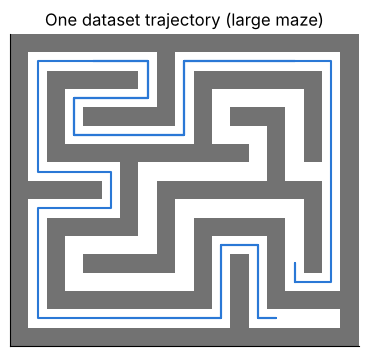

The dataset visits 144 of the 144 open cells of the large maze.


In [3]:
def collect_dataset(env, num_trajs=1000, traj_len=200, policy="navigate", noise=0.2, seed=0):
    """Returns {'obs': (N, T+1), 'actions': (N, T)} arrays of state / action ids."""
    rng = np.random.default_rng(seed)
    dq = env.true_q_dist() if policy == "navigate" else None
    obs = np.zeros((num_trajs, traj_len + 1), dtype=np.int64)
    acts = np.zeros((num_trajs, traj_len), dtype=np.int64)
    for n in range(num_trajs):
        s = rng.integers(env.num_states)
        a = rng.integers(NUM_ACTIONS)
        w = rng.integers(env.num_states)  # current waypoint
        obs[n, 0] = s
        for t in range(traj_len):
            if policy == "navigate":
                while w == s:
                    w = rng.integers(env.num_states)
                if rng.random() < noise:
                    a = rng.integers(NUM_ACTIONS)
                else:
                    best = np.flatnonzero(dq[s, :, w] == dq[s, :, w].min())
                    a = rng.choice(best)
            elif rng.random() > 0.75:  # sticky random walk
                a = rng.integers(NUM_ACTIONS)
            acts[n, t] = a
            s = env.step(s, a)
            obs[n, t + 1] = s
    return {"obs": obs, "actions": acts}


def sample_batch(dataset, batch_size, rng, pairs="offset", random_subgoals=False):
    """In-trajectory index triples i <= k < j (Algorithm 1 of the paper).

    pairs="paper":  i, j ~ Unif{0..T-1} with i < j, exactly as in Algorithm 1.
    pairs="offset": i uniform, then j uniform in (i, T]  (slightly more short chunks; our default).
    random_subgoals: also return a random dataset state/action, for the subgoal ablation (Fig. 6).
    """
    obs, acts = dataset["obs"], dataset["actions"]
    n, t = acts.shape
    traj = rng.integers(n, size=batch_size)
    if pairs == "paper":
        a = rng.integers(t, size=batch_size)
        b = rng.integers(t - 1, size=batch_size)
        b = b + (b >= a)  # two distinct indices in 0..T-1
        i, j = np.minimum(a, b), np.maximum(a, b)
    else:
        i = rng.integers(t, size=batch_size)
        j = i + 1 + (rng.random(batch_size) * (t - i)).astype(np.int64)
    k = i + (rng.random(batch_size) * (j - i)).astype(np.int64)
    out = {"traj": traj, "s_i": obs[traj, i], "a_i": acts[traj, i], "s_next": obs[traj, i + 1],
           "s_k": obs[traj, k], "a_k": acts[traj, k], "s_j": obs[traj, j], "i": i, "k": k, "j": j}
    if random_subgoals:
        rt, rk = rng.integers(n, size=batch_size), rng.integers(t, size=batch_size)
        out["s_k"], out["a_k"] = obs[rt, rk], acts[rt, rk]
    return out


env = ENVS["large"]
data = collect_dataset(env, seed=0)
rc = np.array([env.cells[s] for s in data["obs"][0]])
plt.figure(figsize=(4.5, 4.5))
plt.imshow(env.grid, cmap="Greys", vmin=0, vmax=1.6)
plt.plot(rc[:, 1], rc[:, 0], color=COLORS["trl"], lw=1.5)
plt.title("One dataset trajectory (large maze)"); plt.xticks([]); plt.yticks([]); plt.grid(False)
plt.show()
print(f"The dataset visits {len(np.unique(data['obs']))} of the {env.num_states} open cells of the large maze.")

**What the picture shows.** The blue line is the path of one of the 1,000 trajectories in the dataset. It wanders between random waypoints and makes random moves, so it is not a good path to any particular goal. The printed line checks that the dataset as a whole covers every open cell.

## 4. The agents (tabular)

My TRL, TD and MC update the same table `Q[s, a, g]` with the same sampled batches. **They differ only in the target**, so the comparison isolates the value-update rule, as in Section 5.1 of the paper.

* **TRL:** `target = left * right`, where `left = Q[s_i, a_i, s_k]` (or $\gamma^{k-i}$ if $k-i\le1$) and `right = max_a' Q[s_k, a', s_j]` (or $\gamma^{j-k}$ if $j-k\le1$, and $1$ if $s_k=s_j$).
* **TD:** `target = γ` if $s_{i+1}=s_j$, otherwise `γ · max_a' Q[s_{i+1}, a', s_j]`.
* **MC:** `target = γ^(j-i)`.

**How the max over subgoals is taken.** The paper's tabular operator (Eq. 9) is a hard max over subgoals, as in Floyd–Warshall. In a deterministic maze with the table starting at 0 and exact base cases, *every* TRL target is a lower bound on the true value: a product of lower bounds along a real path. So the exact update $Q \leftarrow \max(Q, \text{target})$ can never over-estimate, and it is what we use by default (`hard_max=True`).

The paper replaces the max with **expectile regression** (κ = 0.7) plus **distance re-weighting**. It needs these because a *neural network's* errors can be positive, and a hard max would exploit them. In a table this soft version, $Q \leftarrow Q + \text{lr}\cdot w\cdot(\text{target}-Q)$ with expectile weight $w$, averages many under-estimating targets. It settles well below the max, so distances come out far too long, which in an earlier version of this notebook made TRL look worse than TD-1. It is kept as `hard_max=False`, and section 6b compares the paper's recipe with our adaptations. TD and MC use the ordinary averaging update (lr 0.5).

*Discrete-action note:* the paper (continuous actions) uses the dataset action $a_k$ at the subgoal. With 4 discrete actions we can take Eq. 10's $\max_{a'}$ exactly; `action_max=False` restores the paper's version. When $k=i$ the subgoal is $s_i$ itself, so the action must stay $a_i$.

The table starts at 0 ("unreachable"); the paper notes this initialisation is required for the transitive operator to converge.

In [4]:
class TabularAgent:
    def __init__(self, method, num_states, gamma=0.99, expectile=0.9, lam=1.0, lr=0.5, action_max=True,
                 cap=True, random_subgoals=False, n_step=1, hard_max=None, goal_one=True):
        """cap: cap the re-weighting distance at j - i (our addition, see below).
        random_subgoals: subgoal ablation - s_k is a random dataset state, not one between s_i and s_j.
        n_step: TD-n baseline (method="td"); n_step=1 is ordinary TD.
        hard_max: exact max update Q <- max(Q, target) (Eq. 9). Default: on for TRL, off for TD/MC.
        goal_one: value 1 when the subgoal is already the goal (our small addition)."""
        assert method in ("trl", "td", "mc")
        self.method, self.gamma, self.lr, self.action_max = method, gamma, lr, action_max
        self.cap, self.random_subgoals, self.n_step, self.goal_one = cap, random_subgoals, n_step, goal_one
        self.hard_max = (method == "trl") if hard_max is None else hard_max
        self.obs = None  # set by train(); TD-n looks n steps ahead in the trajectory
        self.expectile = expectile if method == "trl" else 0.5
        self.lam = lam if method == "trl" else 0.0
        self.Q = np.zeros((num_states, NUM_ACTIONS, num_states))

    def act(self, s, g, rng=None):
        q = self.Q[s, :, g]
        return (q + 1e-9 * (rng or np.random).random(q.shape)).argmax(-1)  # random tie-breaking

    def distance(self, s, g):
        return np.log(np.maximum(self.Q[s, :, g].max(-1), 1e-12)) / math.log(self.gamma)

    def update(self, b):
        Q, gamma = self.Q, self.gamma
        s_i, a_i, s_j, i, j = b["s_i"], b["a_i"], b["s_j"], b["i"], b["j"]
        if self.method == "trl":
            s_k, a_k, k = b["s_k"], b["a_k"], b["k"]
            if self.random_subgoals:  # no index structure: only the one-step pair is a base case
                q_kj = Q[s_k, :, s_j].max(-1) if self.action_max else Q[s_k, a_k, s_j]
                target = np.where(j - i == 1, gamma, Q[s_i, a_i, s_k] * q_kj)
            else:
                left = np.where(k - i <= 1, gamma ** (k - i), Q[s_i, a_i, s_k])
                q_kj = Q[s_k, a_k, s_j]
                if self.action_max:
                    q_kj = np.where(k > i, Q[s_k, :, s_j].max(-1), q_kj)
                right = np.where(j - k <= 1, gamma ** (j - k), q_kj)
                if self.goal_one:
                    right = np.where((k > i) & (s_k == s_j), 1.0, right)  # subgoal is the goal: V(g, g) = gamma^0
                target = left * right
        elif self.method == "td":
            n = np.minimum(self.n_step, j - i)  # clip n at the goal, as in the paper
            s_n = b["s_next"] if self.n_step == 1 else self.obs[b["traj"], i + n]
            target = np.where(s_n == s_j, gamma ** n, gamma ** n * Q[s_n, :, s_j].max(-1))
        else:
            target = gamma ** (j - i)

        if self.hard_max:  # every target is a lower bound on Q*, so taking the max is safe and exact
            np.maximum.at(Q.reshape(-1), np.ravel_multi_index((s_i, a_i, s_j), Q.shape), target)
            return 0.0
        pred = Q[s_i, a_i, s_j]
        err = target - pred
        w = np.where(err > 0, self.expectile, 1 - self.expectile)           # expectile
        if self.lam > 0:                                                     # distance re-weighting
            d_est = np.log(np.maximum(pred, 1e-12)) / math.log(gamma)
            if self.cap:
                d_est = np.minimum(d_est, j - i)                             # j-i upper-bounds the distance
            w = w / (1 + d_est) ** self.lam
        flat = np.ravel_multi_index((s_i, a_i, s_j), Q.shape)                # average duplicate entries
        uniq, inv = np.unique(flat, return_inverse=True)
        Q.reshape(-1)[uniq] += self.lr * np.bincount(inv, weights=w * err) / np.bincount(inv)
        return float((w * err ** 2).mean())

### The paper-faithful agent

This is the paper's recipe (Eq. 12 and Algorithm 1) with nothing changed except that the network is replaced by a table of numbers, one per (cell, move, goal):

* **Outputs and loss:** each entry stores a logit, the value is its sigmoid, and the loss is the expectile-weighted **binary cross-entropy** (BCE), as in the paper's experiments.
* **Target values** come from a separate **target table**, updated by Polyak averaging at rate 0.005 (the paper's target network).
* **Distance weighting** $1/(1+\log_\gamma Q)^{\lambda}$ uses the current estimate, with λ = 1.
* **Subgoal move:** the dataset action $a_k$. **Sampling:** $i, j \sim \mathrm{Unif}\{0,\dots,T-1\}$ with $i<j$, then $k \sim \mathrm{Unif}\{i,\dots,j-1\}$. **Base cases:** only the two in the paper.
* **Optimizer:** Adam, applied to the entries in each batch (a table has no shared weights).

Three settings have to be chosen for a table, and the paper itself tunes the first per task (its Table 5):
* **Expectile κ = 0.9.** With the paper's 0.7, the soft max is too weak for our noisy data (about 35% success on the medium maze).
* **Adam step size 0.1.** The paper's 0.0003 is for a network whose weights are shared by all states; a table entry is only updated when it is sampled, so with 0.0003 almost nothing is learned (0% success).
* **Start value:** logit −10, so every value starts at about 0 ("unreachable"), as the paper requires for the tabular operator to converge (Section 4.1). Starting at 0.5, like an untrained network, gives 0–5% success, because values the data never reaches stay too high.

In [5]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))


class PaperAgent:
    """Transitive RL exactly as in the paper (Eq. 12, Algorithm 1), with a table instead of a network.

    Q(s, a, g) = sigmoid(logit[s, a, g]); loss = w * |kappa - 1(Q > y)| * BCE(Q, y), with
    y = Q_target(s_i, a_i, s_k) * Q_target(s_k, a_k, s_j)   (gamma^(k-i) / gamma^(j-k) for 0- or 1-step pieces)
    w = 1 / (1 + log_gamma Q(s_i, a_i, s_j))^lam            (distance weighting, no gradient through w)
    Q_target is a separate table updated by Polyak averaging (rate 0.005), and the optimizer is Adam.
    """

    def __init__(self, num_states, gamma=0.99, kappa=0.9, lam=1.0, lr=0.1, tau=0.005, init_logit=-10.0):
        self.gamma, self.kappa, self.lam, self.lr, self.tau = gamma, kappa, lam, lr, tau
        self.logit = np.full((num_states, NUM_ACTIONS, num_states), init_logit)  # Q ~ 0: "unreachable"
        self.target = self.logit.copy()
        self.m, self.v, self.count = np.zeros(self.logit.size), np.zeros(self.logit.size), np.zeros(self.logit.size)

    @property
    def Q(self):
        return sigmoid(self.logit)

    def act(self, s, g, rng=None):
        q = self.logit[s, :, g]
        return (q + 1e-9 * (rng or np.random).random(q.shape)).argmax(-1)

    def distance(self, s, g):
        return np.log(sigmoid(self.logit[s, :, g]).max(-1)) / math.log(self.gamma)

    def update(self, b):
        gamma, Qt = self.gamma, lambda *idx: sigmoid(self.target[idx])
        s_i, a_i, s_k, a_k, s_j, i, k, j = (b[x] for x in ["s_i", "a_i", "s_k", "a_k", "s_j", "i", "k", "j"])
        left = np.where(k - i <= 1, gamma ** (k - i), Qt(s_i, a_i, s_k))
        right = np.where(j - k <= 1, gamma ** (j - k), Qt(s_k, a_k, s_j))
        y = left * right                                                    # target from the target table
        q = sigmoid(self.logit[s_i, a_i, s_j])
        w = np.abs(self.kappa - (q > y)) / (1 + np.log(q) / math.log(gamma)) ** self.lam
        flat = np.ravel_multi_index((s_i, a_i, s_j), self.logit.shape)
        grad = np.bincount(flat, weights=w * (q - y) / len(y), minlength=self.logit.size)  # d(BCE) / d(logit)
        # Adam on the entries in this batch (a table's version of a network's Adam, like PyTorch's SparseAdam)
        idx = np.unique(flat)
        self.count[idx] += 1
        self.m[idx] = 0.9 * self.m[idx] + 0.1 * grad[idx]
        self.v[idx] = 0.999 * self.v[idx] + 0.001 * grad[idx] ** 2
        c = self.count[idx]
        self.logit.reshape(-1)[idx] -= self.lr * (self.m[idx] / (1 - 0.9 ** c)) / (
            np.sqrt(self.v[idx] / (1 - 0.999 ** c)) + 1e-8)
        self.target += self.tau * (self.logit - self.target)                # Polyak-averaged target table

### Diagram: one Transitive RL update

Left: a real piece of a dataset trajectory. Transitive RL learns the value of the whole piece (start to goal) from the values of its two halves, split at a subgoal from the same trajectory. Right: why this is faster. TD passes value back one step per update, so an 8-step path needs 8 chained updates. Transitive RL joins two halves at a time, so 8 steps need only 3 levels.

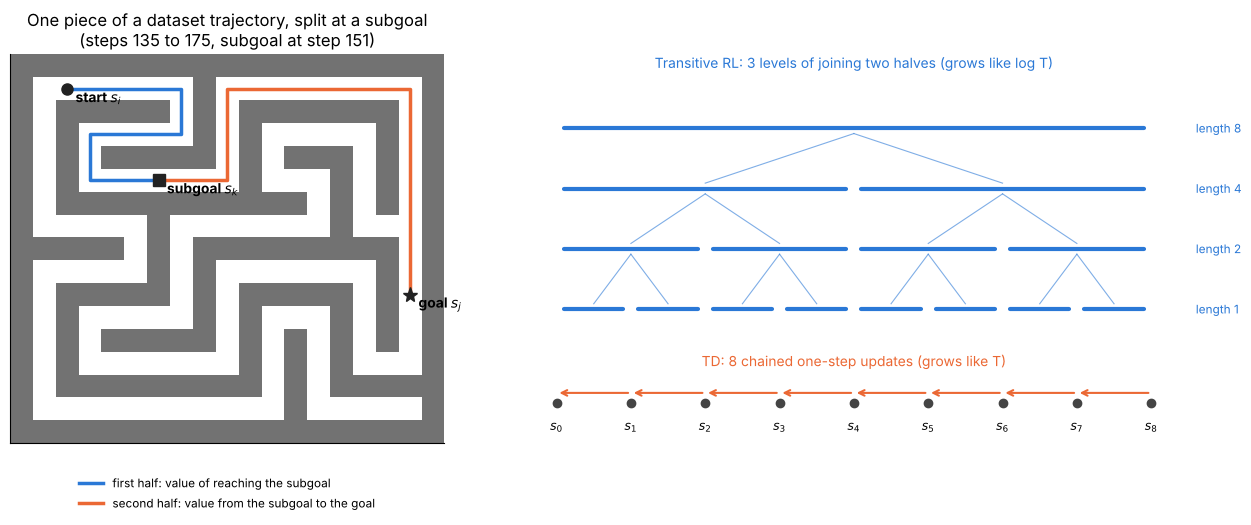

In [6]:
# Diagram 1: one update of Transitive RL on a real dataset trajectory (large maze).
env = ENVS["large"]
# Pick a clean piece: 40 steps that never revisit a cell and end 40 steps from where they start.
n, i = next((n, i) for n in range(len(data["obs"])) for i in range(0, 150, 5)
            if len(set(data["obs"][n][i:i + 41])) == 41 and env.dist[data["obs"][n][i], data["obs"][n][i + 40]] >= 40)
traj, j = data["obs"][n], i + 40
k = i + 16
fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 1.3]})
ax = axes[0]
ax.imshow(env.grid, cmap="Greys", vmin=0, vmax=1.6)
for (a, b), col, lab in [((i, k), COLORS["trl"], "first half: value of reaching the subgoal"),
                         ((k, j), COLORS["td"], "second half: value from the subgoal to the goal")]:
    rc = np.array([env.cells[s] for s in traj[a:b + 1]])
    ax.plot(rc[:, 1], rc[:, 0], color=col, lw=2.5, label=lab)
for idx, mk, name in [(i, "o", "start $s_i$"), (k, "s", "subgoal $s_k$"), (j, "*", "goal $s_j$")]:
    r, c = env.cells[traj[idx]]
    ax.plot(c, r, mk, color="#222", ms=11 if mk == "*" else 8)
    ax.annotate(name, (c, r), xytext=(6, -10), textcoords="offset points", fontsize=10, weight="bold")
ax.set_title(f"One piece of a dataset trajectory, split at a subgoal\n(steps {i} to {j}, subgoal at step {k})")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.2), fontsize=8.5, frameon=False)
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)

# Diagram 2: how many chained updates a path of 8 steps needs (TD: a chain, TRL: a tree).
ax = axes[1]
ax.set_xlim(-0.5, 8.5); ax.set_ylim(-0.6, 5.2); ax.axis("off")
for x in range(9):
    ax.plot(x, 0, "o", color="#444", ms=6)
    ax.text(x, -0.4, f"$s_{x}$", ha="center", fontsize=9)
for x in range(8):  # TD: each value needs the one next to it
    ax.annotate("", (x, 0.15), (x + 1, 0.15), arrowprops=dict(arrowstyle="->", color=COLORS["td"], lw=1.5))
ax.text(4, 0.55, "TD: 8 chained one-step updates (grows like T)", ha="center", color=COLORS["td"], fontsize=10)
for level, span in enumerate([1, 2, 4, 8]):  # TRL: pieces join in pairs
    y = 1.4 + 0.9 * level
    for a in range(0, 8, span):
        ax.plot([a + 0.1, a + span - 0.1], [y, y], color=COLORS["trl"], lw=3, solid_capstyle="round")
        if span > 1:  # this piece is made by joining the two pieces below it
            for x in (a + span / 4, a + 3 * span / 4):
                ax.plot([x, a + span / 2], [y - 0.9 + 0.08, y - 0.08], color=COLORS["trl"], lw=0.8, alpha=0.6)
    ax.text(8.6, y, f"length {span}", va="center", fontsize=8.5, color=COLORS["trl"])
ax.text(4, 5.0, "Transitive RL: 3 levels of joining two halves (grows like log T)", ha="center",
        color=COLORS["trl"], fontsize=10)
plt.tight_layout(); plt.show()

## 5. Evaluation

* **Success rate:** 200 fixed (start, goal) pairs at least 5 steps apart; the greedy policy $\arg\max_a Q(s,a,g)$ must reach the goal within 100 / 300 / 600 steps (medium / large / giant).
* **Optimal-action rate:** over *all* (state, goal) pairs, how often the greedy action is a shortest-path action.
* **Path ratio:** steps taken divided by optimal steps, on successful tasks.
* **Distance error:** median $|\hat d - d^*|$ over all pairs.

In [7]:
MAX_EPISODE_STEPS = {"medium": 100, "large": 300, "giant": 600}


def make_eval_tasks(env, num_tasks=200, min_dist=5, seed=123):
    rng = np.random.default_rng(seed)
    pairs = np.argwhere((env.dist >= min_dist) & np.isfinite(env.dist))
    sel = pairs[rng.choice(len(pairs), size=num_tasks, replace=False)]
    return sel[:, 0], sel[:, 1]


def evaluate(agent, env, starts, goals, max_steps):
    rng = np.random.default_rng(0)  # fixed tie-breaking -> reproducible numbers
    s, done = starts.copy(), starts == goals
    steps = np.zeros(len(s), dtype=np.int64)
    for _ in range(max_steps):
        if done.all():
            break
        s = np.where(done, s, env.next_state[s, agent.act(s, goals, rng)])
        steps += ~done
        done |= s == goals
    opt = env.dist[starts, goals]
    n = env.num_states
    ss, gg = np.meshgrid(np.arange(n), np.arange(n), indexing="ij")
    m = ss != gg
    ss, gg = ss[m], gg[m]
    dq = env.true_q_dist()[ss, :, gg]
    a = agent.act(ss, gg, rng)
    return {"success": float(done.mean()),
            "path_ratio": float((steps[done] / opt[done]).mean()) if done.any() else float("nan"),
            "opt_action": float((dq[np.arange(len(ss)), a] == dq.min(-1)).mean()),
            "dist_err": float(np.median(np.abs(agent.distance(ss, gg) - env.dist[ss, gg])))}


def train(method, layout, steps, seed=0, batch_size=1024, n_evals=20, pairs="offset", **agent_kwargs):
    env = ENVS[layout]
    rng = np.random.default_rng(seed)
    data = collect_dataset(env, seed=seed)
    starts, goals = make_eval_tasks(env)
    if method == "paper":  # the paper's recipe always uses the paper's sampling
        agent, pairs = PaperAgent(env.num_states, **agent_kwargs), "paper"
    else:
        agent = TabularAgent(method, env.num_states, **agent_kwargs)
    agent.obs = data["obs"]
    random_subgoals = agent_kwargs.get("random_subgoals", False)
    curve = []
    for step in range(1, steps + 1):
        agent.update(sample_batch(data, batch_size, rng, pairs, random_subgoals))
        if step % (steps // n_evals) == 0:
            curve.append(dict(step=step, **evaluate(agent, env, starts, goals, MAX_EPISODE_STEPS[layout])))
    return agent, curve


t0 = time.time()
agent, curve = train("trl", "large", 5000)
print(f"Transitive RL on the large maze: {curve[-1]['success']:.1%} of test tasks solved after 5,000 updates "
      f"({time.time() - t0:.0f} seconds)")

Transitive RL on the large maze: 99.0% of test tasks solved after 5,000 updates (4 seconds)


## 6. Experiments: my method vs paper-faithful TRL vs TD vs MC

Each maze gets an update budget that grows with its size (the giant maze gets 100k updates). Tie-breaking between equal-valued actions uses a fixed random seed, so every number and figure is reproducible. `SEEDS = [0]` keeps the notebook to a few minutes; set `SEEDS = [0, 1, 2]` for error bars (the README reports 3 seeds, and seeds agree within about 1%).

In [8]:
SEEDS = [0]
STEPS = {"medium": 10000, "large": 20000, "giant": 100000}

results = {}  # (layout, method) -> list of (agent, curve)
t0 = time.time()
for layout, steps in STEPS.items():
    for method in METHODS:
        results[(layout, method)] = [train(method, layout, steps, seed=s) for s in SEEDS]
        final = np.mean([c[-1]["success"] for _, c in results[(layout, method)]])
        print(f"{layout} maze, {LABELS[method]}: {final:.1%} of test tasks solved   ({time.time() - t0:.0f}s elapsed)")

medium maze, My method (TRL, exact max): 100.0% of test tasks solved   (4s elapsed)


medium maze, Paper-faithful TRL: 67.0% of test tasks solved   (14s elapsed)


medium maze, TD learning (one step): 100.0% of test tasks solved   (21s elapsed)


medium maze, Monte Carlo: 8.0% of test tasks solved   (25s elapsed)


large maze, My method (TRL, exact max): 99.5% of test tasks solved   (34s elapsed)


large maze, Paper-faithful TRL: 76.0% of test tasks solved   (53s elapsed)


... (2 outputs left out)

giant maze, My method (TRL, exact max): 78.5% of test tasks solved   (112s elapsed)


giant maze, Paper-faithful TRL: 19.0% of test tasks solved   (648s elapsed)


giant maze, TD learning (one step): 63.0% of test tasks solved   (695s elapsed)


giant maze, Monte Carlo: 1.5% of test tasks solved   (726s elapsed)


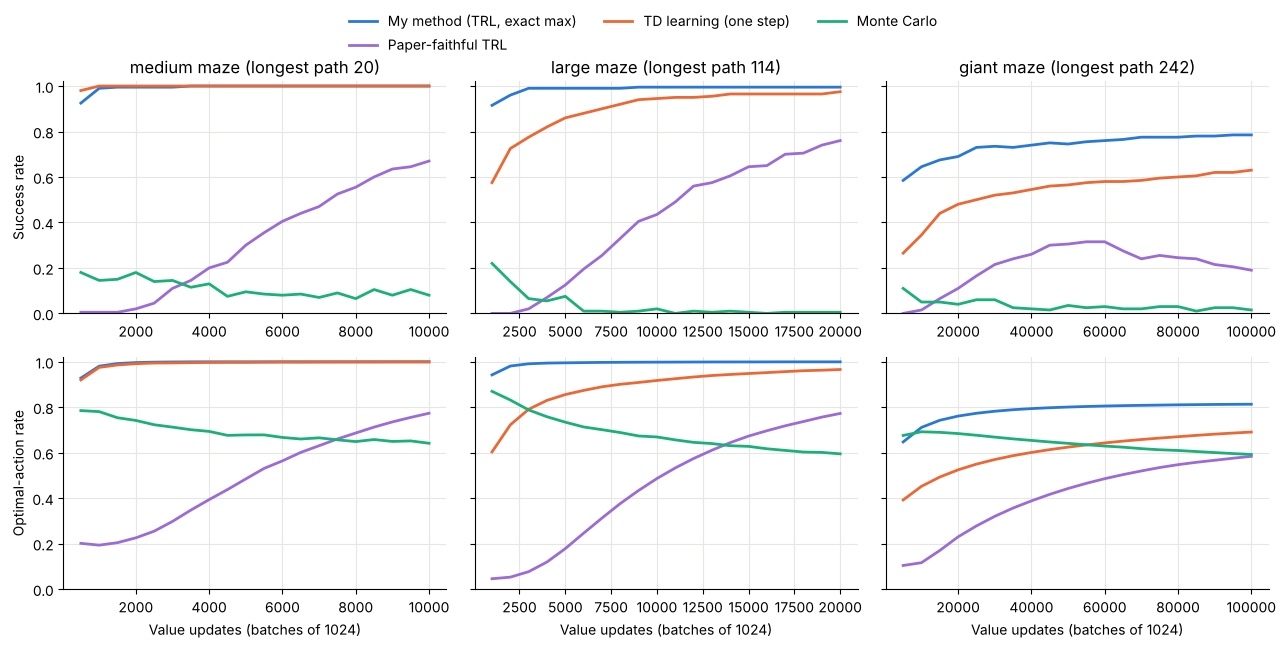

**Final results after training**

| Maze | Method | Test tasks solved | Best move chosen (all state-goal pairs) | Path length compared with the shortest path | Error in the learned distance to the goal |
|---|---|---|---|---|---|
| medium maze | My method (TRL, exact max) | 100.0% | 100.0% | 1.00 times | 0 steps |
| medium maze | Paper-faithful TRL | 67.0% | 77.4% | 1.00 times | 839 steps |
| medium maze | TD learning (one step) | 100.0% | 99.9% | 1.00 times | 0 steps |
| medium maze | Monte Carlo | 8.0% | 64.1% | 1.04 times | 26 steps |
| large maze | My method (TRL, exact max) | 99.5% | 100.0% | 1.00 times | 0 steps |
| large maze | Paper-faithful TRL | 76.0% | 77.3% | 1.01 times | 495 steps |
| large maze | TD learning (one step) | 97.5% | 96.6% | 1.00 times | 0 steps |
| large maze | Monte Carlo | 0.5% | 59.5% | 1.00 times | 19 steps |
| giant maze | My method (TRL, exact max) | 78.5% | 81.3% | 1.09 times | 0 steps |
| giant maze | Paper-faithful TRL | 19.0% | 58.4% | 1.06 times | 820 steps |
| giant maze | TD learning (one step) | 63.0% | 69.1% | 1.11 times | 221 steps |
| giant maze | Monte Carlo | 1.5% | 59.2% | 1.07 times | 30 steps |

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharey="row")
for col, layout in enumerate(STEPS):
    for row, (key, ylabel) in enumerate([("success", "Success rate"), ("opt_action", "Optimal-action rate")]):
        ax = axes[row, col]
        for m in METHODS:
            curves = [c for _, c in results[(layout, m)]]
            x = [p["step"] for p in curves[0]]
            v = np.array([[p[key] for p in c] for c in curves])
            ax.plot(x, v.mean(0), color=COLORS[m], lw=2, label=LABELS[m])
            ax.fill_between(x, v.mean(0) - v.std(0), v.mean(0) + v.std(0), color=COLORS[m], alpha=0.15, lw=0)
        ax.set_ylim(0, 1.02)
        if row == 0:
            ax.set_title(f"{layout} maze (longest path {int(ENVS[layout].dist.max())})")
        else:
            ax.set_xlabel("Value updates (batches of 1024)")
        if col == 0:
            ax.set_ylabel(ylabel)
h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc="upper center", ncol=3, frameon=False)
plt.tight_layout(rect=(0, 0, 1, 0.94)); plt.show()

rows = []
for (layout, m), runs in results.items():
    f = {k: np.nanmean([c[-1][k] for _, c in runs]) for k in ["success", "opt_action", "path_ratio", "dist_err"]}
    rows.append([f"{layout} maze", LABELS[m], f"{f['success']:.1%}", f"{f['opt_action']:.1%}",
                 f"{f['path_ratio']:.2f} times", f"{f['dist_err']:.0f} steps"])
show_table(["Maze", "Method", "Test tasks solved", "Best move chosen (all state-goal pairs)",
            "Path length compared with the shortest path", "Error in the learned distance to the goal"],
           rows, "Final results after training")

**How to read the figure and table.** In the figure, each column is one maze and each line is one method; the x-axis is the number of training updates.
* **Top row:** the share of the 200 test tasks (start and goal pairs) that the method solves, by always taking its best-rated move.
* **Bottom row:** over every possible position and goal, how often the method's chosen move is one of the best moves.

In the table, *path length compared with the shortest path* is 1.00 times when every solved task used a shortest path. *Error in the learned distance* is the typical gap between the number of steps the method thinks it needs and the true number.

**Reading the results**

* On the short **medium** maze, TD and TRL both reach 100%.
* On **large** (paths up to 114 steps), TRL ends slightly ahead (99.5% vs 97.5%) and gets there much faster (see below).
* On **giant** (paths up to 242 steps), TRL is clearly ahead for the whole 100k-update budget: 78.5% vs 63% on the test tasks, and 81% vs 69% optimal actions.
* **TRL's distance estimates are exact** (median error 0 on every maze). TD's are still far off on the giant maze (221 steps), because one-step backups have not yet propagated over the longest paths.
* **MC fails.** It learns the noisy *behaviour* policy's distances and cannot stitch trajectories, so its greedy policy gets stuck.
* **Paper-faithful TRL** (the paper's recipe exactly, in a table) solves 67% / 76% / 19% of the test tasks, and its learned distances are hundreds of steps off. Its soft BCE update and slow target table spread value far more slowly than the exact max, and on the giant maze it peaks at about 32% after 55,000 updates and then gets worse. Section 6b looks at this in detail.

### Where TRL beats TD: long-horizon goals

The average success rate hides *where* the methods differ. Below, every method is scored on 3,000 random (start, goal) pairs, grouped by the true shortest-path distance. This is the paper's central claim: TD needs $O(T)$ chained backups to get a correct value $T$ steps away, while divide and conquer needs about $O(\log T)$, so the gap should grow with the distance to the goal.

**large maze: share of tasks solved, by distance to the goal (after 20,000 updates)**

| Goal is this many steps away | My method (TRL, exact max) | Paper-faithful TRL | TD learning (one step) | Monte Carlo | Number of tasks |
|---|---|---|---|---|---|
| 1 to 25 | 100% | 90% | 100% | 9% | 1065 |
| 25 to 50 | 100% | 83% | 100% | 0% | 824 |
| 50 to 100 | 100% | 56% | 96% | 2% | 1007 |
| 100 to 150 | 95% | 0% | 58% | 0% | 77 |

**giant maze: share of tasks solved, by distance to the goal (after 100,000 updates)**

| Goal is this many steps away | My method (TRL, exact max) | Paper-faithful TRL | TD learning (one step) | Monte Carlo | Number of tasks |
|---|---|---|---|---|---|
| 1 to 25 | 98% | 55% | 99% | 20% | 444 |
| 25 to 50 | 97% | 27% | 95% | 3% | 458 |
| 50 to 100 | 96% | 18% | 83% | 0% | 881 |
| 100 to 150 | 89% | 23% | 61% | 0% | 768 |
| 150 to 250 | 36% | 4% | 6% | 0% | 441 |

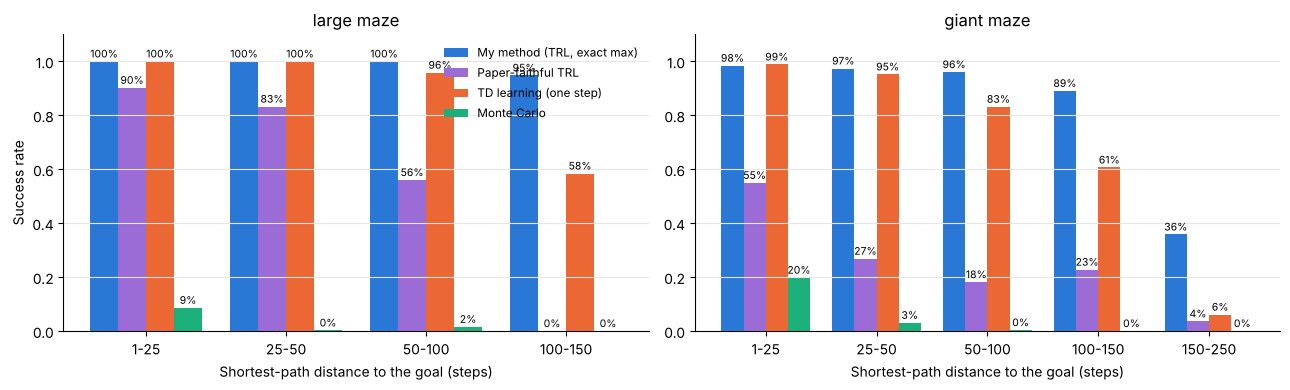

In [10]:
BUCKETS = [(1, 25), (25, 50), (50, 100), (100, 150), (150, 250)]


def success_by_distance(agent, env, n_pairs=3000, max_steps=600, seed=0):
    rng = np.random.default_rng(seed)
    n = env.num_states
    idx = rng.choice(n * n, n_pairs, replace=False)
    s, g = idx // n, idx % n
    keep = s != g
    s, g = s[keep], g[keep]
    cur, done = s.copy(), np.zeros(len(s), dtype=bool)
    for _ in range(max_steps):
        cur = np.where(done, cur, env.next_state[cur, agent.act(cur, g, rng)])
        done |= cur == g
    d = env.dist[s, g]
    out = {}
    for lo, hi in BUCKETS:
        sel = (d >= lo) & (d < hi)
        out[(lo, hi)] = (done[sel].mean() if sel.any() else float("nan"), int(sel.sum()))
    return out


fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, layout in zip(axes, ["large", "giant"]):
    env = ENVS[layout]
    table = {m: success_by_distance(results[(layout, m)][0][0], env) for m in METHODS}
    buckets = [b for b in BUCKETS if table["trl"][b][1] > 0]
    show_table(["Goal is this many steps away"] + [LABELS[m] for m in METHODS] + ["Number of tasks"],
               [[f"{b[0]} to {b[1]}"] + [f"{table[m][b][0]:.0%}" for m in METHODS] + [table["trl"][b][1]]
                for b in buckets],
               f"{layout} maze: share of tasks solved, by distance to the goal (after {STEPS[layout]:,} updates)")
    x = np.arange(len(buckets))
    for off, m in zip([-0.3, -0.1, 0.1, 0.3], METHODS):
        vals = [table[m][b][0] for b in buckets]
        bars = ax.bar(x + off, vals, width=0.2, color=COLORS[m], label=LABELS[m])
        for bar, v in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width() / 2, v + 0.015, f"{v:.0%}", ha="center", fontsize=7.5)
    ax.set_xticks(x, [f"{lo}-{hi}" for lo, hi in buckets])
    ax.set_xlabel("Shortest-path distance to the goal (steps)")
    ax.set_ylim(0, 1.1); ax.set_title(f"{layout} maze"); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Success rate"); axes[0].legend(frameon=False, fontsize=8.5)
plt.tight_layout(); plt.show()

In [11]:
# Learning speed: how many updates each method needs to reach a success level on the 200 test tasks.
def updates_to_reach(curve, level):
    return next((p["step"] for p in curve if p["success"] >= level), None)

rows = []
for layout, level in [("large", 0.9), ("giant", 0.5), ("giant", 0.6)]:
    row = {m: updates_to_reach(results[(layout, m)][0][1], level) for m in ["trl", "td"]}
    fmt = lambda v: f"{v:,} updates" if v else f"not reached in {STEPS[layout]:,}"
    rows.append([f"{layout} maze", f"{level:.0%} of tasks solved", fmt(row["trl"]), fmt(row["td"])])
show_table(["Maze", "Target", "Transitive RL needs", "TD learning needs"], rows, "How fast each method learns")

**How fast each method learns**

| Maze | Target | Transitive RL needs | TD learning needs |
|---|---|---|---|
| large maze | 90% of tasks solved | 1,000 updates | 7,000 updates |
| giant maze | 50% of tasks solved | 5,000 updates | 25,000 updates |
| giant maze | 60% of tasks solved | 10,000 updates | 80,000 updates |

**How to read the figure and tables.** Each bar is the share of tasks solved for goals at that distance (x-axis, in steps along the shortest path). Blue is Transitive RL, orange is TD learning and green is Monte Carlo. The "how fast" table gives the number of training updates each method needed before it first solved that share of the 200 test tasks.

**What this shows.** For goals within about 50 steps, TRL and TD are about equal (giant, 1–25 steps: 98% vs 99%). **The further the goal, the bigger TRL's advantage:**
* Giant maze, goals 100–150 steps away: **89% vs 61%**. Goals 150–250 steps away: **36% vs 6%**.
* Large maze, goals 100–150 steps away: **95% vs 58%**.
* Paper-faithful TRL falls off quickly with distance: on the large maze it solves 90% of goals within 25 steps but 0% of goals 100–150 steps away.
* **Learning speed:** TRL needs 5–8× fewer updates to reach the same success. Large maze 90%: 1k vs 7k updates. Giant maze 60%: 10k vs 80k.

This is exactly the paper's claim: divide and conquer reduces the number of chained backups from $O(T)$ to about $O(\log T)$, so its advantage grows with the horizon $T$.

### Animation: how the value spreads during training

Each panel shows, for one goal ★ in the large maze, the value each method has learned for every cell (bright = the goal is known to be close, dark = not known to be reachable yet). TD spreads value outwards one step per update; Transitive RL joins known pieces, so value reaches far cells much sooner. The GIF is saved as `value_spreading.gif`.

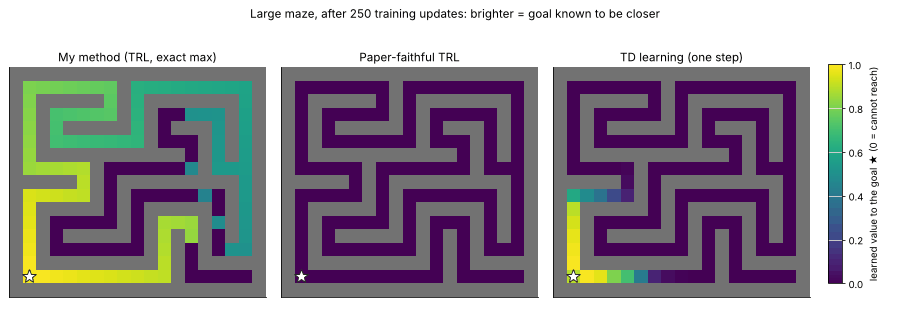

In [12]:
# Animation: how the learned value to one goal spreads through the maze during training.
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display


def value_snapshots(method, layout, goal, steps, every, **kw):
    env, rng = ENVS[layout], np.random.default_rng(0)
    data = collect_dataset(env, seed=0)
    agent = PaperAgent(env.num_states) if method == "paper" else TabularAgent(method, env.num_states, **kw)
    pairs = "paper" if method == "paper" else "offset"
    snaps = []
    for step in range(1, steps + 1):
        agent.update(sample_batch(data, 1024, rng, pairs))
        if step % every == 0:
            snaps.append(agent.Q[:, :, goal].max(-1).copy())
    return snaps


layout, goal_cell = "large", (15, 1)
env = ENVS[layout]
goal = env.cell_to_id[goal_cell]
spread_methods = ["trl", "paper", "td"]
EVERY, N_STEPS = 250, 10000
snaps = {m: value_snapshots(m, layout, goal, N_STEPS, EVERY) for m in spread_methods}

fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
fig.subplots_adjust(left=0.01, right=0.89, top=0.85, bottom=0.02, wspace=0.06)
images = {}
for ax, m in zip(axes, spread_methods):
    img = np.full(env.grid.shape, np.nan)
    images[m] = (ax.imshow(img, cmap="viridis", vmin=0, vmax=1), img)
    ax.imshow(np.where(env.grid, 1.0, np.nan), cmap="Greys", vmin=0, vmax=1.6)
    ax.plot(goal_cell[1], goal_cell[0], "*", color="white", ms=15, mec="#222")
    ax.set_title(LABELS[m]); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.colorbar(images["trl"][0], cax=fig.add_axes([0.91, 0.12, 0.015, 0.68]),
             label="learned value to the goal ★ (0 = cannot reach)")
title = fig.suptitle("")


def draw(t):
    for m in spread_methods:
        im, img = images[m]
        for s, (r, c) in enumerate(env.cells):
            img[r, c] = snaps[m][t][s]
        im.set_data(img)
    title.set_text(f"Large maze, after {(t + 1) * EVERY:,} training updates: brighter = goal known to be closer")
    return []


frames = list(range(len(snaps["trl"]))) + [len(snaps["trl"]) - 1] * 10
FuncAnimation(fig, draw, frames=frames).save("value_spreading.gif", writer=PillowWriter(fps=8), dpi=70)
plt.close(fig)
display(Image(filename="value_spreading.gif"))

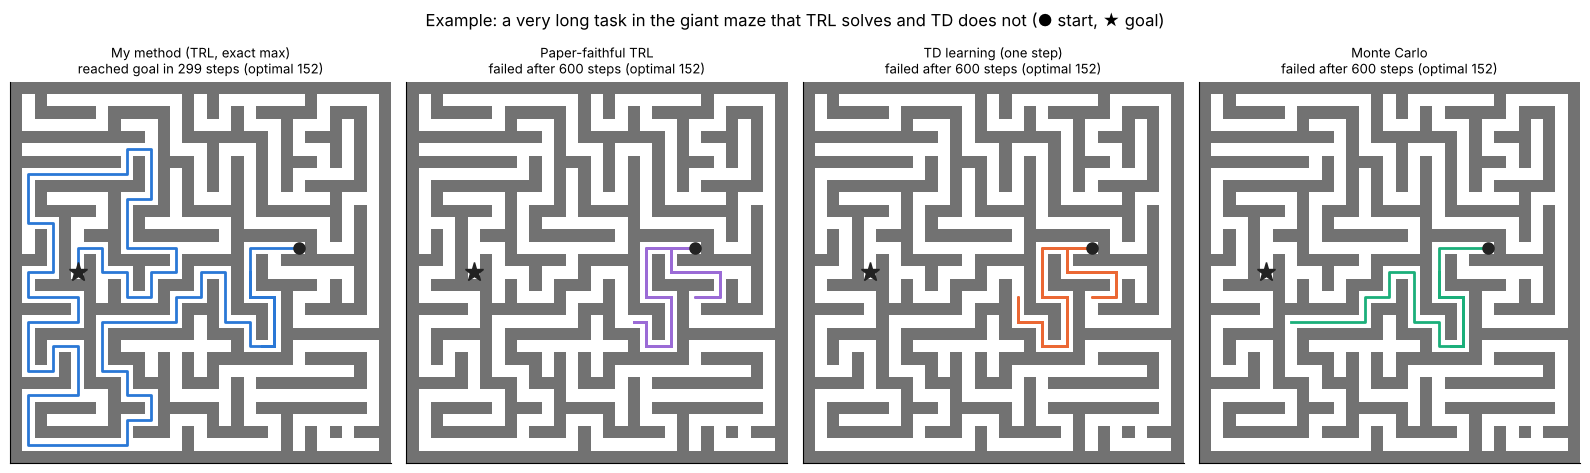

In [13]:
def rollout(agent, env, s, g, max_steps, seed=0):
    rng = np.random.default_rng(seed)
    path = [s]
    for _ in range(max_steps):
        if s == g:
            break
        s = int(env.next_state[s, agent.act(np.array([s]), np.array([g]), rng)[0]])
        path.append(s)
    return path


# An illustration (not a fair sample - the distance chart above is the fair comparison):
# in a fixed random order, the first very long task (shortest path >= 150) that TRL solves and TD does not.
layout = "giant"
env = ENVS[layout]
agents = {m: results[(layout, m)][0][0] for m in METHODS}
pairs = np.argwhere(env.dist >= 150)
pairs = pairs[np.random.default_rng(1).permutation(len(pairs))]
solved = lambda m, s, g: rollout(agents[m], env, s, g, MAX_EPISODE_STEPS[layout])[-1] == g
s, g = next((s, g) for s, g in pairs[:2000] if solved("trl", s, g) and not solved("td", s, g))

fig, axes = plt.subplots(1, 4, figsize=(16, 4.8))
for ax, (m, ag) in zip(axes, agents.items()):
    path = rollout(ag, env, s, g, MAX_EPISODE_STEPS[layout])
    rc = np.array([env.cells[p] for p in path])
    ax.imshow(env.grid, cmap="Greys", vmin=0, vmax=1.6)
    ax.plot(rc[:, 1], rc[:, 0], color=COLORS[m], lw=2)
    ax.plot(*env.cells[s][::-1], "o", color="#222", ms=8)
    ax.plot(*env.cells[g][::-1], "*", color="#222", ms=14)
    status = f"reached goal in {len(path) - 1}" if path[-1] == g else f"failed after {len(path) - 1}"
    ax.set_title(f"{LABELS[m]}\n{status} steps (optimal {int(env.dist[s, g])})", fontsize=9.5)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle("Example: a very long task in the giant maze that TRL solves and TD does not (● start, ★ goal)")
plt.tight_layout(rect=(0, 0, 1, 0.94)); plt.show()

**What the picture shows.** One very long task in the giant maze (● start, ★ goal). Each panel draws the path one method takes when it always picks its best-rated move. The title says whether it reached the goal and in how many steps, next to the shortest possible number of steps.

### Animation: the methods side by side

The same task as above, played step by step by my method, paper-faithful TRL and TD. The GIF is also saved next to the notebook as `trl_vs_td_giant.gif`.

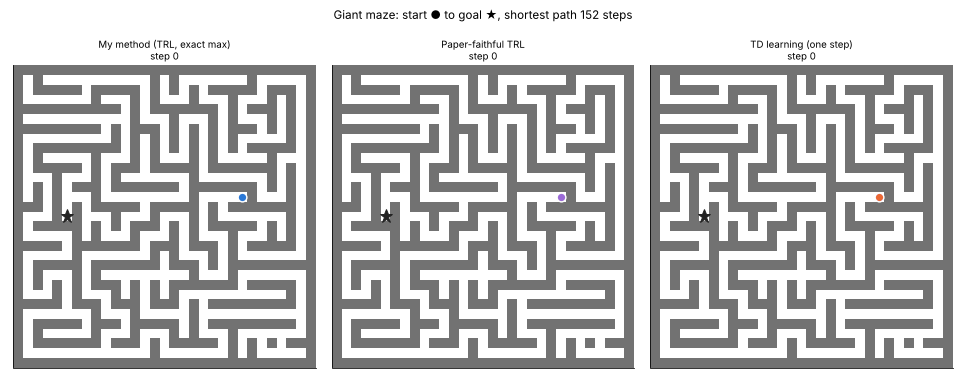

In [14]:
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display


def animate_rollouts(env, methods, s, g, max_steps, filename, stride=2, fps=20):
    """Animate greedy rollouts of several agents from s to g, side by side, and save a GIF."""
    paths = {m: np.array([env.cells[p] for p in rollout(agents[m], env, s, g, max_steps)]) for m in methods}
    n_frames = max(len(p) for p in paths.values())
    frames = list(range(0, n_frames, stride)) + [n_frames - 1] * fps  # hold the last frame for 1 s

    fig, axes = plt.subplots(1, len(methods), figsize=(4.6 * len(methods), 5.4))
    artists = {}
    for ax, m in zip(axes, methods):
        ax.imshow(env.grid, cmap="Greys", vmin=0, vmax=1.6)
        ax.plot(*env.cells[s][::-1], "o", color="#222", ms=8)
        ax.plot(*env.cells[g][::-1], "*", color="#222", ms=14)
        trail, = ax.plot([], [], color=COLORS[m], lw=2)
        dot, = ax.plot([], [], "o", color=COLORS[m], ms=9, mec="white", mew=1.5)
        label = ax.set_title(LABELS[m], fontsize=10)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        artists[m] = (trail, dot, label)
    fig.suptitle(f"Giant maze: start ● to goal ★, shortest path {int(env.dist[s, g])} steps")

    def draw(t):
        out = []
        for m, (trail, dot, label) in artists.items():
            p = paths[m][: t + 1]
            trail.set_data(p[:, 1], p[:, 0])
            dot.set_data([p[-1, 1]], [p[-1, 0]])
            done = t >= len(paths[m]) - 1
            if done and tuple(p[-1]) == env.cells[g]:
                status = f"reached the goal in {len(paths[m]) - 1} steps"
            elif done:
                status = f"failed: still lost after {len(paths[m]) - 1} steps"
            else:
                status = f"step {t}"
            label.set_text(f"{LABELS[m]}\n{status}")
            out += [trail, dot, label]
        return out

    plt.tight_layout(rect=(0, 0, 1, 0.92))
    FuncAnimation(fig, draw, frames=frames).save(filename, writer=PillowWriter(fps=fps), dpi=70)
    plt.close(fig)
    return filename


gif = animate_rollouts(env, ["trl", "paper", "td"], s, g, MAX_EPISODE_STEPS[layout], "trl_vs_td_giant.gif", stride=3)
display(Image(filename=gif))

### What each part of TRL contributes (large maze)

Change one part of Transitive RL at a time: the exact max update, the distance weighting, the best move at the subgoal, and subgoals taken from the same trajectory. The last is the paper's subgoal ablation (Fig. 6): the subgoal $s_k$ becomes a random dataset state instead of one between $s_i$ and $s_j$.

**What each part of Transitive RL contributes**

| Version (large maze) | Test tasks solved | Best move chosen | Error in the learned distance |
|---|---|---|---|
| Our Transitive RL (exact max update) | 99.5% | 100.0% | 0 steps |
| Soft update (paper's style) instead of exact max | 97.5% | 99.2% | 80 steps |
| Soft update without distance weighting | 23.5% | 90.6% | 23 steps |
| Dataset's action at the subgoal, not the best one | 99.5% | 99.9% | 0 steps |
| Random subgoals instead of ones from the trajectory | 90.5% | 94.4% | 0 steps |
| Soft update and random subgoals | 22.5% | 36.2% | 2695 steps |

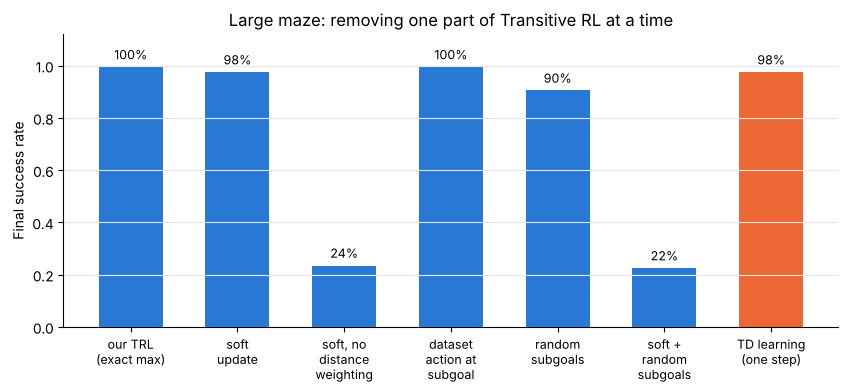

In [15]:
ablations = {
    "Our Transitive RL (exact max update)": {},
    "Soft update (paper's style) instead of exact max": {"hard_max": False},
    "Soft update without distance weighting": {"hard_max": False, "lam": 0.0},
    "Dataset's action at the subgoal, not the best one": {"action_max": False},
    "Random subgoals instead of ones from the trajectory": {"random_subgoals": True},
    "Soft update and random subgoals": {"hard_max": False, "random_subgoals": True},
}
abl = {}
for name, kw in ablations.items():
    _, c = train("trl", "large", STEPS["large"], seed=0, **kw)
    abl[name] = c[-1]

show_table(["Version (large maze)", "Test tasks solved", "Best move chosen", "Error in the learned distance"],
           [[n, f"{a['success']:.1%}", f"{a['opt_action']:.1%}", f"{a['dist_err']:.0f} steps"] for n, a in abl.items()],
           "What each part of Transitive RL contributes")

names = list(abl) + ["TD learning (one step)"]
vals = [abl[n]["success"] for n in abl] + [results[("large", "td")][0][1][-1]["success"]]
ABL_LABEL = dict(zip(names, ["our TRL\n(exact max)", "soft\nupdate", "soft, no\ndistance\nweighting",
                             "dataset\naction at\nsubgoal", "random\nsubgoals", "soft +\nrandom\nsubgoals",
                             "TD learning\n(one step)"]))
plt.figure(figsize=(10, 3.8))
bars = plt.bar(range(len(vals)), vals, color=[COLORS["trl"]] * len(abl) + [COLORS["td"]], width=0.6)
for b, v in zip(bars, vals):
    plt.text(b.get_x() + b.get_width() / 2, v + 0.03, f"{v:.0%}", ha="center", fontsize=9)
plt.xticks(range(len(vals)), [ABL_LABEL[n] for n in names], fontsize=9)
plt.ylim(0, 1.12); plt.ylabel("Final success rate"); plt.title("Large maze: removing one part of Transitive RL at a time")
plt.grid(axis="x", visible=False); plt.show()

**How to read the table and figure.** Each row (and blue bar) is our Transitive RL with one part changed or removed, trained on the large maze for the same 20,000 updates. The orange bar is TD learning for comparison. *Best move chosen* is over every position and goal; *error in the learned distance* is the typical gap between the learned and the true number of steps.

* **Exact max vs soft update.** The soft (paper-style) version still works, but its distances are far too long (typical error 80 steps), and it loses some long goals.
* **Distance weighting is essential for the soft version:** without it success falls to 23.5%. The exact max does not need it.
* **In-trajectory subgoals are essential for the soft version.** With random subgoals, soft TRL collapses to 22.5%, reproducing the paper's Fig. 6. With the exact max, random subgoals still work (90.5%): a table cannot over-estimate, so the danger the paper guards against (a max exploiting over-estimated values) does not arise. They are still worse than in-trajectory subgoals (99.5%), because a random state is rarely on a short path.

## 6b. Final tabular results: the paper's method vs ours

Three versions, from the paper's method to ours, so each step's effect is measured:

| Version | What it does |
|---|---|
| **Paper-faithful TRL** | The paper's recipe exactly (BCE loss, expectile, distance weighting, target table, Adam, dataset move at the subgoal, the paper's sampling), on a table. |
| **Paper + exact max** | The same sampling, subgoals and dataset move, but each value keeps the best target found so far, Q ← max(Q, target). This is the paper's own update for tables (Eq. 9), used instead of its neural-network loss. |
| **My method** | Paper + exact max, plus three small changes: the best of the 4 moves at the subgoal instead of the dataset's move, value 1 when the subgoal is already the goal, and slightly more short pieces in sampling. |

All versions use the same data, number of updates and test tasks.

In [16]:
LADDER = {
    "Paper-faithful TRL": ("paper", {}),
    "Paper + exact max":  ("trl", dict(hard_max=True, action_max=False, goal_one=False, pairs="paper")),
    "My method":          ("trl", {}),
}
paper_runs = {}
t0 = time.time()
for layout in ["medium", "large", "giant"]:
    for name, (method, kw) in LADDER.items():
        agent, curve = train(method, layout, STEPS[layout], seed=0, **kw)
        far = success_by_distance(agent, ENVS[layout]).get((100, 150), (float("nan"), 0))[0]
        paper_runs[(layout, name)] = (curve, far)
        print(f"{layout} maze, {name}: done ({time.time() - t0:.0f}s elapsed)")

medium maze, Paper-faithful TRL: done (9s elapsed)


medium maze, Paper + exact max: done (13s elapsed)


medium maze, My method: done (18s elapsed)


large maze, Paper-faithful TRL: done (37s elapsed)


large maze, Paper + exact max: done (43s elapsed)


large maze, My method: done (52s elapsed)


giant maze, Paper-faithful TRL: done (375s elapsed)


giant maze, Paper + exact max: done (400s elapsed)


giant maze, My method: done (437s elapsed)


**medium maze: the paper's method vs ours**

| Version | Test tasks solved | Far goals solved (100 to 150 steps away) | Best move chosen | Error in the learned distance |
|---|---|---|---|---|
| Paper-faithful TRL | 67.0% | no such goals | 77.4% | 839 steps |
| Paper + exact max | 100.0% | no such goals | 100.0% | 0 steps |
| My method | 100.0% | no such goals | 100.0% | 0 steps |

**large maze: the paper's method vs ours**

| Version | Test tasks solved | Far goals solved (100 to 150 steps away) | Best move chosen | Error in the learned distance |
|---|---|---|---|---|
| Paper-faithful TRL | 76.0% | 0% | 77.3% | 495 steps |
| Paper + exact max | 100.0% | 96% | 100.0% | 0 steps |
| My method | 99.5% | 95% | 100.0% | 0 steps |

**giant maze: the paper's method vs ours**

| Version | Test tasks solved | Far goals solved (100 to 150 steps away) | Best move chosen | Error in the learned distance |
|---|---|---|---|---|
| Paper-faithful TRL | 19.0% | 23% | 58.4% | 820 steps |
| Paper + exact max | 80.0% | 90% | 81.4% | 0 steps |
| My method | 78.5% | 89% | 81.3% | 0 steps |

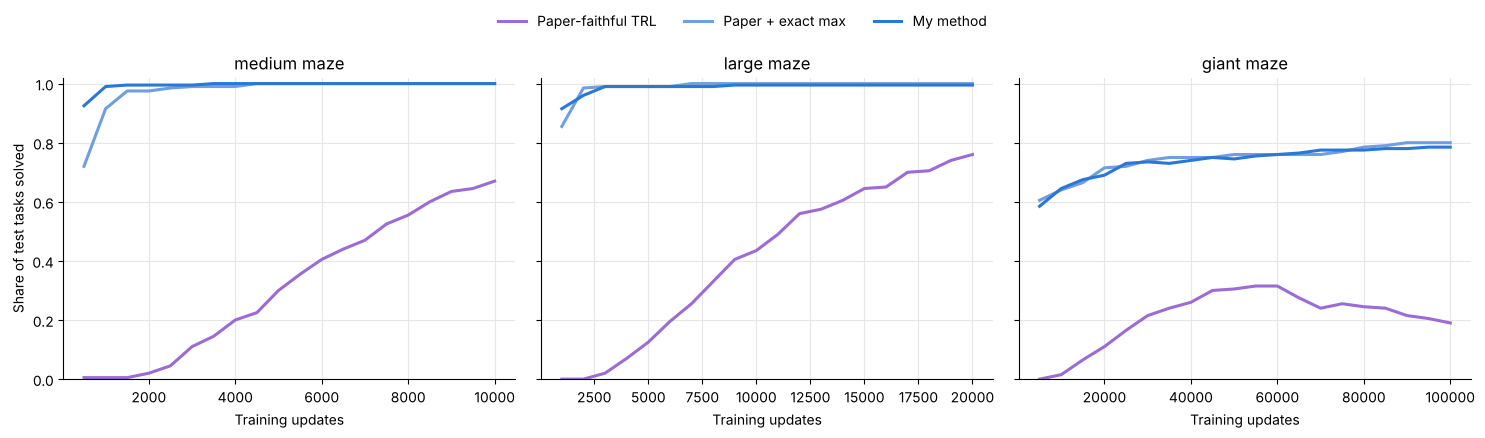

In [17]:
names = list(LADDER)
for layout in ["medium", "large", "giant"]:
    rows = []
    for n in names:
        curve, far = paper_runs[(layout, n)]
        rows.append([n, f"{curve[-1]['success']:.1%}", "no such goals" if np.isnan(far) else f"{far:.0%}",
                     f"{curve[-1]['opt_action']:.1%}", f"{curve[-1]['dist_err']:.0f} steps"])
    show_table(["Version", "Test tasks solved", "Far goals solved (100 to 150 steps away)", "Best move chosen",
                "Error in the learned distance"], rows, f"{layout} maze: the paper's method vs ours")

cols = [COLORS["paper"], "#6f9fe0", COLORS["trl"]]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), sharey=True)
for ax, layout in zip(axes, ["medium", "large", "giant"]):
    for n, col in zip(names, cols):
        curve = paper_runs[(layout, n)][0]
        ax.plot([p["step"] for p in curve], [p["success"] for p in curve], color=col, lw=2.2, label=n)
    ax.set_title(f"{layout} maze"); ax.set_xlabel("Training updates"); ax.set_ylim(0, 1.02)
axes[0].set_ylabel("Share of test tasks solved")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=3, frameon=False)
plt.tight_layout(rect=(0, 0, 1, 0.92)); plt.show()

**How to read the tables and figure.** Each row is one version. *Far goals* are test pairs 100 to 150 steps apart (the medium maze has none). *Best move chosen* is over every position and goal. The figure shows the share of test tasks solved during training.

**What this shows**
* **Paper-faithful TRL works, but slowly.** On the medium and large mazes it is still improving when training stops (67% and 76%). On the giant maze it peaks at about 32% and then gets worse, and it solves almost no goals more than 100 steps away on the large maze. Its learned distances are hundreds of steps off.
* **Why.** Each update only nudges a value toward its target (a BCE gradient step), and the targets come from a target table that moves only 0.5% per update. Long distances are built from short ones, so these small, delayed steps compound, and the noise of the soft updates is larger than the 1% gap between a good move and a slightly worse one.
* **Replacing only the update rule fixes everything.** "Paper + exact max" keeps the paper's sampling, subgoals and dataset moves, but keeps the best target found so far. It solves 100% / 100% / 80% of the tasks and learns the exact distances. This is the paper's own update for tables (Eq. 9); the soft BCE loss exists because a neural network cannot take an exact max safely.
* **My other changes add nothing measurable** (100% / 99.5% / 78.5%), so the result rests on the exact max update alone.

## Summary

* TRL replaces TD's one-step backup with a **divide-and-conquer** update built on the triangle inequality, using **in-trajectory subgoals**. In a table the max over subgoals is taken exactly (the paper's Eq. 9). The paper's soft version (**expectile regression** and **distance re-weighting**) is designed for neural networks and is compared in section 6b.
* On grid mazes, tabular TRL learns exact distances and **matches or beats TD-1 on every maze**: 100% vs 100% medium, 99.5% vs 97.5% large, 78.5% vs 63% giant. The gap grows with the distance to the goal (giant, 150–250 steps: 36% vs 6%), and TRL needs 5–8× fewer updates. MC fails because it cannot stitch trajectories.
* **Paper vs ours (section 6b):** the paper's recipe, run faithfully on a table, solves 67% / 76% / 19% of the medium / large / giant test tasks. Replacing only its soft BCE update with the exact max update (the paper's own rule for tables, Eq. 9) gives 100% / 100% / 80% with exact distances. My other small changes add nothing on top of that.

**Reference:** S. Park, A. Oberai, P. Atreya, S. Levine. *Transitive RL: Value Learning via Divide and Conquer.* ICLR 2026.